# C3 · Explain and defend our BI study: extreme hospital stays, flagged at admission

Business Intelligence IIB423T-1 · Universidad del Desarrollo · Instructor: Tomás Fontecilla Correa
GROUP_01 · Members: Matías López, Cristóbal Ramírez

**Question.** Using only what is known on the day a patient is admitted to a FONASA public hospital, can we flag the stays likely to become *extreme* (longer than the cut-off of their GRD) well enough for bed managers to start discharge planning early, and does this beat the simple rule a bed manager can apply today (flag every emergency admission)?

**How to read this notebook.** It is the final, integrated pipeline of the study: inputs → quality and EDA → preparation → split → frozen labels → model comparison and reference → one test run → final views → conclusions → decision record. It was executed top to bottom and saved with its outputs; the reviewer does not need to run it. The source data are **not** in the repository (C3 rule); section 1 gives their links, versions and checksums. Earlier stage notebooks (W1, C1, W2, C2, W3) are kept as the development record; section 9 says what each contributed and what was later corrected.

| Section | Content | Rubric |
|---|---|---|
| 1 | Data card: sources, versions, periods, unit of observation, variables and units | A, B |
| 2 | Quality summary of the fields used | A, B |
| 3 | Preparation, its effect on the records, and EDA of the prepared stays | A, B, D |
| 4 | Chronological split and train-only labels | A, D |
| 5 | Model comparison on validation (answer to the C2 feedback) and choice | A, D |
| 6 | One final run on the test set | A |
| 7 | Final views, drawn with the shared visual system (W3 rules) | C |
| 8 | Conclusions, recommendation and limits | A |
| 9 | Decision record, feedback use, W3 design selection, contributions and AI use | D |

## 1. Data card

| Item | Description |
|---|---|
| Source | FONASA public GRD files, from the *Catálogo de Datos* tab of the FONASA dashboard (https://public.tableau.com/views/PropuestaTableroGRD/PropuestaTableroGRD): `GRD_PUBLICO_2023.zip` (https://www.fonasa.cl/assets/datos-abiertos/Financiamiento_y_Gasto_en_Salud/GRD_PUBLICO_2023.zip) and `GRD_PUBLICO_2024.zip` (https://adjuntos.fonasa.gob.cl/assets/datos-abiertos/Financiamiento_y_Gasto_en_Salud/GRD_PUBLICO_2024.zip) |
| Versions | 2023 file extracted by FONASA on 04-09-2024; 2024 file extracted on 16-05-2025 |
| Reference tables | FONASA dictionary *Tablas maestras bases GRD* (IR-GRD codes, retrieved 25-09-2026) and MINSAL health facilities (datos.gob.cl, *establecimientos de salud vigentes*) |
| Period | Discharges in 2023 and 2024 (one file per discharge year); admissions from 2022 to 2024 |
| One row | One hospital discharge episode (stay) of one patient in a public hospital grouped by GRD |
| Records | 2,125,400 episodes in the two files (1,039,587 + 1,085,813), 72 hospitals |
| Reduction (C1 script `01_extraer_grd.py`) | Keeps 23 original columns and adds age in years, number of diagnoses, number of procedures and file year; drops the encrypted patient identifier and the date of birth; no rows filtered |
| Key variables and units | Admission and discharge dates (day), length of stay = discharge minus admission (days), GRD code (IR-GRD 3.0, 6 digits) and relative weight, admission type, origin, admitting unit, insurance, sex, age (years), hospital code |
| Format differences | 2023: UTF-16, dates DD-MM-YYYY; 2024: Latin-1, dates YYYY-MM-DD; GRD weight with decimal comma (W1 finding) |

The cell below checks that the local copies of the four input files are the same bytes used in C1, W2 and C2 (SHA-256). To re-run, the files must be placed in `GROUP_01_C1/data/extracted/` and `GROUP_01_C1/data/reference/`; these folders are excluded from the repository.

In [1]:
import sys, platform, hashlib, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib, sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, accuracy_score,
                             average_precision_score)

SEED = 2026
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()      # GROUP_01_C3/
REPO = BASE.parent
EXT, REF = REPO / "GROUP_01_C1/data/extracted", REPO / "GROUP_01_C1/data/reference"   # local only, not in the repository
OUT, FIG = BASE / "outputs/tables", BASE / "outputs/figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / "GROUP_01_W3/notebooks"))
import w3_style as S                      # the visual system (W3 rules R1-R8), shared by every final view
S.apply_rcparams()
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "|", platform.system(), "| seed", SEED)

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
EXPECTED_SHA = {   # published in the C1 README; checked again in W2 and C2
    "grd_2023_extracto.csv.gz": "dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878",
    "grd_2024_extracto.csv.gz": "7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0",
    "Tablas_maestras_bases_GRD.xlsx": "29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a",
    "establecimientos_datosgobcl.csv": "21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176"}
inputs = pd.DataFrame([{"file": p.name, "MB": round(p.stat().st_size/1e6, 1), "sha256": sha256(p)}
                       for p in [EXT/"grd_2023_extracto.csv.gz", EXT/"grd_2024_extracto.csv.gz",
                                 REF/"Tablas_maestras_bases_GRD.xlsx", REF/"establecimientos_datosgobcl.csv"]])
inputs["same file as C1, W2 and C2"] = [EXPECTED_SHA[f] == h for f, h in zip(inputs.file, inputs.sha256)]
assert inputs["same file as C1, W2 and C2"].all(), "Inputs differ from C1/W2/C2"
inputs

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Linux | seed 2026


,file,MB,sha256,"same file as C1, W2 and C2"
0,grd_2023_extracto.csv.gz,40.2,dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878,True
1,grd_2024_extracto.csv.gz,43.2,7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0,True
2,Tablas_maestras_bases_GRD.xlsx,0.1,29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a,True
3,establecimientos_datosgobcl.csv,2.5,21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176,True


## 2. Quality summary of the fields used

Only the 13 fields the study uses are loaded. The table gives, for each field, its meaning, when it becomes known and the share of empty or unknown values over all 2,125,400 episodes. Fields known only at discharge (GRD code, weight, discharge date) define the outcome and are never model inputs.

In [2]:
FMT = {2023: "%d-%m-%Y", 2024: "%Y-%m-%d"}           # date format differs by file (W1 finding)
USE = ["COD_HOSPITAL", "SEXO", "PREVISION", "TIPO_PROCEDENCIA", "TIPO_INGRESO", "SERVICIOINGRESO", "HOSPPROCEDENCIA", "EDAD_ANIOS",
       "TIPO_ACTIVIDAD", "IR_29301_COD_GRD", "IR_29301_PESO", "FECHA_INGRESO", "FECHAALTA"]
parts = []
for y in (2023, 2024):
    d = pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False, usecols=USE)
    d["ADM"] = pd.to_datetime(d.FECHA_INGRESO, format=FMT[y], errors="coerce")
    d["DIS"] = pd.to_datetime(d.FECHAALTA, format=FMT[y], errors="coerce")
    d["FILE_YEAR"] = y
    parts.append(d.drop(columns=["FECHA_INGRESO", "FECHAALTA"]))
g = pd.concat(parts, ignore_index=True); del parts, d
g["LOS"] = (g.DIS - g.ADM).dt.days
g["WEIGHT"] = pd.to_numeric(g.IR_29301_PESO.str.replace(",", ".", regex=False), errors="coerce")
g["AGE"] = pd.to_numeric(g.EDAD_ANIOS, errors="coerce")
dic = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="IR - GRD", header=None, skiprows=1, dtype=str)
dic.columns = ["CODE", "DESCRIPTION"]; dic["CODE6"] = dic.CODE.str.strip().str.zfill(6)

# Quality summary of the fields this study uses (all 2,125,400 episodes, before any exclusion)
EMPTY = {"", "DESCONOCIDO"}
quality = pd.DataFrame({
    "meaning": ["Hospital DEIS code", "Sex", "Insurance category", "Origin of the patient", "Admission type", "Admitting unit",
                "Transferred from (hospital code)", "Age at admission (years)", "Episode type", "GRD code (discharge coding)",
                "GRD relative weight", "Admission date", "Discharge date"],
    "known at": ["admission"]*8 + ["admission", "discharge", "discharge", "admission", "discharge"],
    "% empty or unknown": [round(g[c].isin(EMPTY).mean()*100, 3) for c in USE[:-2]] +
                          [round(g.ADM.isna().mean()*100, 4), round(g.DIS.isna().mean()*100, 4)]}, index=USE)
dup_rows = int(g[USE[:-2] + ["ADM", "DIS"]].duplicated().sum())
print(f"Episodes loaded: {len(g):,} (2023 file {int((g.FILE_YEAR==2023).sum()):,}; 2024 file {int((g.FILE_YEAR==2024).sum()):,}) | "
      f"rows repeated on the 13 study fields: {dup_rows:,} ({dup_rows/len(g):.2%}; kept, as in C1)")
quality

Episodes loaded: 2,125,400 (2023 file 1,039,587; 2024 file 1,085,813) | rows repeated on the 13 study fields: 10,808 (0.51%; kept, as in C1)


,meaning,known at,% empty or unknown
COD_HOSPITAL,Hospital DEIS code,admission,0.0000
SEXO,Sex,admission,0.0070
PREVISION,Insurance category,admission,0.0030
TIPO_PROCEDENCIA,Origin of the patient,admission,0.0000
TIPO_INGRESO,Admission type,admission,0.0050
SERVICIOINGRESO,Admitting unit,admission,0.7320
HOSPPROCEDENCIA,Transferred from (hospital code),admission,89.0500
EDAD_ANIOS,Age at admission (years),admission,0.0030
TIPO_ACTIVIDAD,Episode type,admission,0.0000
IR_29301_COD_GRD,GRD code (discharge coding),discharge,0.0020


## 3. Preparation: from episodes to valid inpatient stays

The same rules and order as C1 and W2: ambulatory surgery (CMA) is out of scope; rows with invalid dates, or a GRD code missing from the FONASA dictionary or without weight, are excluded. The table shows how many rows each rule removed, by file year. Exact repeats and same-day stays are kept (C1 decision: they are plausible records, not errors). The 16 stays of GRD strata too small to benchmark (fewer than 30 cases at code and base level, C1/W2) are handled in section 4, where they get no label.

In [3]:
# Exclusions: same rules and order as C1 and W2 (section 2.3); each row keeps the first reason that applies
g["EXCLUSION"] = ""
def flag(mask, reason):
    m = mask & (g.EXCLUSION == ""); g.loc[m, "EXCLUSION"] = reason
flag(g.TIPO_ACTIVIDAD != "HOSPITALIZACIÓN", "CMA, ambulatory surgery (out of scope)")
flag(g.ADM.isna() | g.DIS.isna() | (g.LOS < 0), "invalid dates")
flag(~g.IR_29301_COD_GRD.isin(dic.CODE6) | g.WEIGHT.isna(), "GRD code not in dictionary or no weight")
flow = (g.groupby(["EXCLUSION", "FILE_YEAR"]).size().unstack(fill_value=0)
        .rename(index={"": "kept: valid inpatient stays"}))
flow["total"] = flow.sum(axis=1)
g["GRD"] = g.IR_29301_COD_GRD; g["BASE_GRD"] = g.GRD.str[:5]; g["HOSP"] = g.COD_HOSPITAL
P = g[g.EXCLUSION == ""].copy(); del g
assert len(P) == 1719718, "valid inpatient stays differ from W2 (1,719,718 before the benchmarkable-stratum step)"
flow

FILE_YEAR,2023,2024,total
EXCLUSION,,,
kept: valid inpatient stays,846013,873705,1719718
"CMA, ambulatory surgery (out of scope)",193544,212041,405585
GRD code not in dictionary or no weight,30,15,45
invalid dates,0,52,52


### 3.1 Distributions of the valid inpatient stays

Length of stay is right-skewed: the median is 3 days, but the 99th percentile is close to 60 days. Emergency admissions are most stays and are longer. These two facts shape the study: extreme stays are a minority that uses a large share of bed-days, and admission type is a strong but crude signal (it is the basis of the reference rule).

Length of stay (days) of valid inpatient stays, by file year


,count,mean,min,median,p90,p99,max,same-day stays %,stays > 30 days %,bed-days (millions)
FILE_YEAR,,,,,,,,,,
2023,846013.0,7.10,0.0,3.0,16.0,58.0,696.0,5.10,3.56,6.01
2024,873705.0,7.05,0.0,3.0,16.0,57.0,661.0,5.27,3.51,6.16


Stays by admission type


,stays,median_LOS,mean_LOS,share_pct
TIPO_INGRESO,,,,
URGENCIA,1058485,5.0,9.15,61.55
PROGRAMADA,361703,2.0,4.22,21.03
OBSTETRICA,299432,2.0,3.21,17.41
DESCONOCIDO,98,2.0,6.02,0.01


Hospitals: 72 | GRD codes: 790 | admissions from 07-01-2022 to 31-12-2024


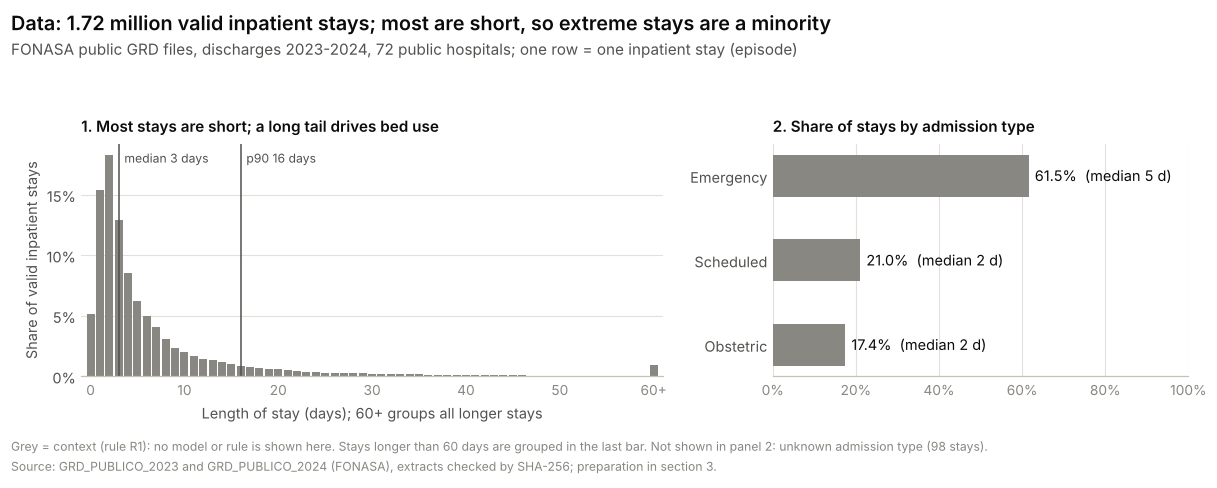

In [4]:
los = P.groupby("FILE_YEAR").LOS.describe(percentiles=[.5, .9, .99]).rename(columns={"50%": "median", "90%": "p90", "99%": "p99"})
los["same-day stays %"] = P.groupby("FILE_YEAR").LOS.apply(lambda s: (s == 0).mean()*100)
los["stays > 30 days %"] = P.groupby("FILE_YEAR").LOS.apply(lambda s: (s > 30).mean()*100)
los["bed-days (millions)"] = P.groupby("FILE_YEAR").LOS.sum()/1e6
los = los.drop(columns=["std"]).round(2)
mix = (P.groupby("TIPO_INGRESO").agg(stays=("LOS", "size"), median_LOS=("LOS", "median"), mean_LOS=("LOS", "mean"))
         .assign(share_pct=lambda d: d.stays/d.stays.sum()*100).sort_values("stays", ascending=False).round(2))
print("Length of stay (days) of valid inpatient stays, by file year"); display(los)
print("Stays by admission type"); display(mix)
print(f"Hospitals: {P.HOSP.nunique()} | GRD codes: {P.GRD.nunique()} | admissions from {P.ADM.min():%d-%m-%Y} to {P.ADM.max():%d-%m-%Y}")

def eda_figure():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1.4, 1], wspace=S.PANEL_GAP + 0.1))
    fig.subplots_adjust(left=0.07, right=0.985, top=0.70, bottom=0.22)
    a, b = axes
    cnt = P.LOS.clip(upper=60).value_counts().sort_index()
    a.bar(cnt.index, cnt.values / len(P) * 100, width=0.85, color=S.REFERENCE, edgecolor=S.SURFACE, linewidth=0)
    for q, lab in [(P.LOS.median(), "median"), (P.LOS.quantile(.9), "p90")]:
        a.axvline(q, color=S.INK2, lw=1); a.text(q + 0.6, a.get_ylim()[1]*0.92, f"{lab} {q:.0f} days", fontsize=S.SIZE_NOTE, color=S.INK2)
    a.set_xlim(-1, 61); a.set_xticks([0, 10, 20, 30, 40, 50, 60]); a.set_xticklabels(["0", "10", "20", "30", "40", "50", "60+"])
    a.set_yticks([0, 5, 10, 15]); a.set_yticklabels(["0%", "5%", "10%", "15%"]); a.set_ylabel("Share of valid inpatient stays"); a.set_xlabel("Length of stay (days); 60+ groups all longer stays")
    a.grid(axis="x", visible=False); a.spines["bottom"].set_visible(True)
    a.set_title("1. Most stays are short; a long tail drives bed use")
    mixp = mix.drop(index="DESCONOCIDO", errors="ignore"); order = mixp.index.tolist()
    y = np.arange(len(order))[::-1]
    b.barh(y, mixp.share_pct.values, height=0.5, color=S.REFERENCE, edgecolor=S.SURFACE, linewidth=0)
    for yi, (k, r) in zip(y, mixp.iterrows()):
        b.text(r.share_pct + 1.5, yi, f"{S.pct(r.share_pct)}  (median {r.median_LOS:.0f} d)", va="center", fontsize=S.SIZE_LABEL, color=S.INK)
    b.set_yticks(y); b.set_yticklabels([S.ADMISSION_TYPE_EN[k] for k in order])
    S.percent_axis(b, S.SCALE_SHARE, "x"); b.spines["bottom"].set_visible(True)
    b.set_title("2. Share of stays by admission type")
    S.frame(fig, "Data: 1.72 million valid inpatient stays; most are short, so extreme stays are a minority",
            f"FONASA public GRD files, discharges 2023-2024, {P.HOSP.nunique()} public hospitals; one row = one inpatient stay (episode)",
            f"Grey = context (rule R1): no model or rule is shown here. Stays longer than 60 days are grouped in the last bar. Not shown in panel 2: unknown admission type ({int(mix.loc['DESCONOCIDO','stays'])} stays).\n"
            "Source: GRD_PUBLICO_2023 and GRD_PUBLICO_2024 (FONASA), extracts checked by SHA-256; preparation in section 3.", legend=False)
    return fig
fig_e = eda_figure(); fig_e.savefig(FIG/"c3_fig0_data_overview.png"); plt.show()

## 4. Chronological split and train-only labels

The W2 split is reused exactly (counts checked against W2). Training uses admissions of Jan-Jun 2023, validation Jul-Sep 2023 and test Jan-Sep 2024; an embargo leaves out Oct-Dec 2023 so that no stay in training or validation is discharged in 2024, and Oct-Dec 2024 admissions are left out because many were not yet discharged when the 2024 file was cut (censoring).

In [5]:
T_CUT = pd.Timestamp("2024-01-01")
P["SPLIT"] = "excluded"
adm, dis = P.ADM, P.DIS
P.loc[(adm >= "2023-01-01") & (adm < "2023-07-01") & (dis < T_CUT), "SPLIT"] = "train"
P.loc[(adm >= "2023-07-01") & (adm < "2023-10-01") & (dis < T_CUT), "SPLIT"] = "validation"
P.loc[(adm >= T_CUT) & (adm < "2024-10-01"), "SPLIT"] = "test"
W2_COUNTS = {"train": 421352, "validation": 214640, "test": 655321}
split = P.groupby("SPLIT").agg(rows=("LOS", "size"), admitted_from=("ADM", "min"), admitted_to=("ADM", "max"),
                               hospitals=("HOSP", "nunique")).loc[["train", "validation", "test", "excluded"]]
split["W2 rows"] = pd.Series(W2_COUNTS)
split["role"] = ["fit the model and the frozen cut-offs", "compare candidates, choose threshold", "one final run of the chosen model",
                 "embargo Oct-Dec 2023 and censored Oct-Dec 2024 admissions; 2022 admissions"]
assert all(split.loc[k, "rows"] == v for k, v in W2_COUNTS.items()), "split differs from W2"
S_ = {k: P[P.SPLIT == k].copy() for k in ("train", "validation", "test")}
split

,rows,admitted_from,admitted_to,hospitals,W2 rows,role
SPLIT,,,,,,
train,421352,2023-01-01,2023-06-30,68,421352.0,fit the model and the frozen cut-offs
validation,214640,2023-07-01,2023-09-30,68,214640.0,"compare candidates, choose threshold"
test,655321,2024-01-01,2024-09-30,72,655321.0,one final run of the chosen model
excluded,428405,2022-01-07,2024-12-31,72,NaN,embargo Oct-Dec 2023 and censored Oct-Dec 2024 admissions; 2022 admissions


### 4.1 Extreme-stay cut-offs, fitted on training stays only

An extreme stay is a stay longer than Q3 + 1.5 × IQR of the length of stay of its GRD code (C1 definition). W2 found that the C1 cut-offs had used all years, including the future test period (leakage), so since W2 they are fitted on training stays only and frozen. The cell rebuilds them and checks that they are identical to the W2 and C2 tables.

In [6]:
K_IQR, MIN_N, UNIT_MIN = 1.5, 30, 500     # unchanged from C1/W2/C2

def build_benchmark(ref, k=K_IQR, min_n=MIN_N):
    def level(key):
        q = ref.groupby(key).LOS.quantile([.25, .75]).unstack(); q.columns = ["Q1", "Q3"]
        q["N"] = ref.groupby(key).size(); q["CUT"] = q.Q3 + k*(q.Q3 - q.Q1)
        r = ref.join(q.CUT, on=key); inl = r[r.LOS <= r.CUT]
        q["EXPECTED"] = inl.groupby(key).LOS.mean(); q["P_OUT"] = (r.LOS > r.CUT).groupby(r[key]).mean()
        return q
    code_, base = level("GRD"), level("BASE_GRD")
    bm = code_.copy(); bm["LEVEL"] = "code"
    small = bm.N < min_n
    fb = base.reindex(bm.index.str[:5]); fb.index = bm.index
    for c in ["CUT", "EXPECTED", "P_OUT"]: bm.loc[small, c] = fb.loc[small, c]
    bm.loc[small, "LEVEL"] = "base GRD fallback"
    bad = small & (fb.N.values < min_n)
    bm.loc[bad, ["CUT", "EXPECTED", "P_OUT"]] = np.nan; bm.loc[bad, "LEVEL"] = "not benchmarkable"
    bm.attrs["base"] = base[base.N >= min_n][["CUT", "EXPECTED", "P_OUT"]]
    return bm

train_raw = S_["train"]
FIT_BM = build_benchmark(train_raw)                     # extreme-stay cut-off per GRD, fitted on train only
AGE_MEDIAN = float(train_raw.AGE.median())
uc = train_raw.SERVICIOINGRESO.value_counts()
UNIT_VOCAB = sorted(uc[uc >= UNIT_MIN].index)
HOSP_VOCAB = sorted(train_raw.HOSP.unique())
def params_fingerprint():
    blob = FIT_BM[["CUT", "EXPECTED"]].to_csv() + FIT_BM.attrs["base"].to_csv() + str(AGE_MEDIAN)
    return hashlib.sha256(blob.encode()).hexdigest()[:16]
FP_FROZEN = params_fingerprint()
c2_bm = pd.read_csv(REPO/"GROUP_01_C2/data/processed/c2_02_frozen_thresholds_by_grd.csv", dtype={"GRD": str}).set_index("GRD")
assert FIT_BM.index.equals(c2_bm.index) and np.allclose(FIT_BM.CUT.fillna(-1), c2_bm.CUT.fillna(-1)), "cut-offs differ from W2/C2"
print("Frozen cut-offs identical to W2 and C2:", len(FIT_BM), "GRD codes | levels:", FIT_BM.LEVEL.value_counts().to_dict(),
      "| fingerprint", FP_FROZEN, "| age median (train)", AGE_MEDIAN, "| admitting units kept", len(UNIT_VOCAB))
print("Example (first 3 GRD codes): cut-off in days")
FIT_BM[["N", "Q1", "Q3", "CUT", "LEVEL"]].head(3)

Frozen cut-offs identical to W2 and C2: 783 GRD codes | levels: {'code': 683, 'base GRD fallback': 84, 'not benchmarkable': 16} | fingerprint 7a96dae3b661e290 | age median (train) 40.0 | admitting units kept 65
Example (first 3 GRD codes): cut-off in days


,N,Q1,Q3,CUT,LEVEL
GRD,,,,,
011011,51,5.0,13.0,25.00,code
011012,80,4.0,15.0,31.50,code
011013,115,7.5,22.0,43.75,code


### 4.2 Admission-time inputs and labels

Inputs are only fields known on the day of admission (W2 feedback 1); a guard stops the notebook if any post-admission field enters. The label uses the discharge date and GRD code, so it is the target only. The table shows the extreme-stay rate in each subset and the share of bed-days those stays use.

In [7]:
ADM_FEATURES = ["AGE", "AGE_BAND", "SEXO", "PREVISION", "TIPO_INGRESO", "TIPO_PROCEDENCIA", "UNIT", "HOSP_ENC",
                "ADM_MONTH", "ADM_WEEKDAY", "TRANSFER_IN"]
AGE_BANDS = [-1, 0, 4, 14, 44, 64, 79, 200]

def transform(d):
    d = d.join(FIT_BM[["CUT", "LEVEL"]], on="GRD")
    unseen = ~d.GRD.isin(FIT_BM.index)
    fb = FIT_BM.attrs["base"].CUT.reindex(d.loc[unseen, "BASE_GRD"]); fb.index = d.index[unseen]
    d.loc[unseen, "CUT"] = fb
    d["LABEL"] = np.where(d.CUT.notna(), (d.LOS > d.CUT).astype(float), np.nan)   # target only, never an input
    d["AGE"] = d.AGE.fillna(AGE_MEDIAN)
    d["AGE_BAND"] = pd.cut(d.AGE, AGE_BANDS).astype(str)
    d["UNIT"] = d.SERVICIOINGRESO.where(d.SERVICIOINGRESO.isin(UNIT_VOCAB), "OTHER")
    d["HOSP_ENC"] = d.HOSP.where(d.HOSP.isin(HOSP_VOCAB), "UNSEEN_HOSPITAL")
    d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month.astype(str), d.ADM.dt.dayofweek.astype(str)
    d["TRANSFER_IN"] = (d.HOSPPROCEDENCIA.str.strip() != "").astype(int)
    return d

Z = {k: transform(S_[k]) for k in ("train", "validation", "test")}
assert params_fingerprint() == FP_FROZEN
POST_ADMISSION = {"GRD", "BASE_GRD", "IR_29301_COD_GRD", "IR_29301_PESO", "WEIGHT", "IR_29301_SEVERIDAD", "IR_29301_MORTALIDAD",
                  "DIAGNOSTICO1", "N_DIAG", "N_PROC", "USOSPABELLON", "TIPOALTA", "SERVICIOALTA", "DIS", "LOS", "CUT", "LEVEL",
                  "LABEL", "ESPECIALIDAD_MEDICA"}
assert not set(ADM_FEATURES) & POST_ADMISSION, "post-admission field in inputs"
prep = pd.DataFrame([{"subset": k, "stays": len(d), "with a label": int(d.LABEL.notna().sum()),
                      "no frozen cut-off (not evaluated)": int(d.LABEL.isna().sum()),
                      "extreme stays": int(d.LABEL.sum()), "extreme-stay rate %": round(float(d.LABEL.mean()*100), 2),
                      "share of bed-days in extreme stays %": round(float(d.loc[d.LABEL == 1, "LOS"].sum() / d.loc[d.LABEL.notna(), "LOS"].sum()*100), 1)}
                     for k, d in Z.items()]).set_index("subset")
print("Inputs (admission-time only):", ADM_FEATURES)
prep

Inputs (admission-time only): ['AGE', 'AGE_BAND', 'SEXO', 'PREVISION', 'TIPO_INGRESO', 'TIPO_PROCEDENCIA', 'UNIT', 'HOSP_ENC', 'ADM_MONTH', 'ADM_WEEKDAY', 'TRANSFER_IN']


,stays,with a label,no frozen cut-off (not evaluated),extreme stays,extreme-stay rate %,share of bed-days in extreme stays %
subset,,,,,,
train,421352,421226,126,26558,6.30,24.3
validation,214640,214565,75,13823,6.44,23.7
test,655321,655093,228,40078,6.12,23.8


### 4.3 Why it matters: bed-days held by extreme stays (test period)

Extreme stays are a minority of stays but hold a large share of bed-days. The days each extreme stay spent beyond the cut-off of its GRD are the part that early discharge planning could act on; the table also expresses them as beds occupied every day of the 274-day admission period (bed-days beyond the cut-off divided by 274). This is an arithmetic equivalence for communication, not an estimate of avoidable days.

In [8]:
te_l = Z["test"][Z["test"].LABEL.notna()]
ext = te_l[te_l.LABEL == 1]
DAYS = (pd.Timestamp("2024-09-30") - pd.Timestamp("2024-01-01")).days + 1      # 274 days of admissions in the test period
excess = float((ext.LOS - ext.CUT).sum())
impact = pd.DataFrame({"value": {
    "test stays with a label (admitted Jan-Sep 2024)": len(te_l),
    "extreme stays": len(ext),
    "extreme stays, % of stays": round(len(ext) / len(te_l) * 100, 1),
    "bed-days, all stays": int(te_l.LOS.sum()),
    "bed-days, extreme stays": int(ext.LOS.sum()),
    "extreme stays, % of bed-days": round(ext.LOS.sum() / te_l.LOS.sum() * 100, 1),
    "bed-days beyond the GRD cut-off (extreme stays)": int(round(excess)),
    "same, as beds occupied every day of the 274-day admission period": round(excess / DAYS),
    "median length of stay, extreme stays (days)": float(ext.LOS.median()),
    "median length of stay, other stays (days)": float(te_l.loc[te_l.LABEL == 0, "LOS"].median())}})
impact.to_csv(OUT / "c3_04_why_it_matters.csv")
impact

,value
test stays with a label (admitted Jan-Sep 2024),655093.0
extreme stays,40078.0
"extreme stays, % of stays",6.1
"bed-days, all stays",4522730.0
"bed-days, extreme stays",1076075.0
"extreme stays, % of bed-days",23.8
bed-days beyond the GRD cut-off (extreme stays),424194.0
"same, as beds occupied every day of the 274-day admission period",1548.0
"median length of stay, extreme stays (days)",19.0
"median length of stay, other stays (days)",3.0


## 5. Model comparison on validation (C2 feedback: report how many models were tried)

C2 trained one model. The instructor asked to report how many models were tried and to compare 3 to 5 candidates. C3 fits **6 configurations from 3 families** on the same training stays and inputs, and compares them on the validation set only: the C2 logistic regression (C = 1), two more regularisation strengths, two decision trees and a random forest (the tree and forest methods of the course). Each candidate gets its own best threshold on validation, by F1, as in C2. The test set is not touched.

In [9]:
CAT_COLS = [c for c in ADM_FEATURES if c != "AGE"]
def encoder():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS), ("num", StandardScaler(), ["AGE"])])
CANDIDATES = [   # (family, configuration, estimator); all use balanced class weights, as in C2
    ("Logistic regression", "C = 1 (C2 model)", LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000)),
    ("Logistic regression", "C = 0.1 (stronger regularisation)", LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000)),
    ("Logistic regression", "C = 10 (weaker regularisation)", LogisticRegression(class_weight="balanced", C=10.0, max_iter=2000)),
    ("Decision tree", "max depth 6, min 200 per leaf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=SEED)),
    ("Decision tree", "max depth 10, min 200 per leaf", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, class_weight="balanced", random_state=SEED)),
    ("Random forest", "100 trees, max depth 12, min 100 per leaf", RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=100,
                       max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
]
tr = Z["train"][Z["train"].LABEL.notna()]; y_tr = tr.LABEL.astype(int).values
va = Z["validation"][Z["validation"].LABEL.notna()]; y_va = va.LABEL.astype(int).values
GRID = np.round(np.arange(0.05, 0.96, 0.01), 2)

def threshold_curve(y, p):
    return pd.DataFrame([{"threshold": t, "precision": precision_score(y, (p >= t).astype(int), zero_division=0),
                          "recall": recall_score(y, (p >= t).astype(int)), "F1": f1_score(y, (p >= t).astype(int)),
                          "flagged %": (p >= t).mean()*100} for t in GRID])

FITTED, CURVES, rows = {}, {}, []
for fam, cfg, est in CANDIDATES:
    name = f"{fam}, {cfg}"
    pipe = Pipeline([("prep", encoder()), ("clf", est)])
    t0 = time.time(); pipe.fit(tr[ADM_FEATURES], y_tr); secs = time.time() - t0
    p = pipe.predict_proba(va[ADM_FEATURES])[:, 1]
    cv = threshold_curve(y_va, p); best = cv.loc[cv.F1.idxmax()]
    FITTED[name], CURVES[name] = pipe, cv
    rows.append({"candidate": name, "family": fam, "PR-AUC (average precision)": average_precision_score(y_va, p),
                 "best threshold": best.threshold, "F1": best.F1, "precision": best.precision, "recall": best.recall,
                 "flagged %": best["flagged %"], "fit seconds": round(secs, 1)})
cmp_val = pd.DataFrame(rows).set_index("candidate")
base_va = (va.TIPO_INGRESO == "URGENCIA").astype(int).values
REF_VAL = {"precision": precision_score(y_va, base_va), "recall": recall_score(y_va, base_va), "F1": f1_score(y_va, base_va),
           "flagged %": base_va.mean()*100}
print(f"Candidates fitted on {len(tr):,} training stays; compared on {len(va):,} validation stays (prevalence {y_va.mean():.2%}).")
print(f"Models tried in C3: {len(CANDIDATES)} configurations from {cmp_val.family.nunique()} families (C2 tried 1).")
print(f"Reference on validation, emergency rule: precision {REF_VAL['precision']:.4f}, recall {REF_VAL['recall']:.4f}, F1 {REF_VAL['F1']:.4f}")
cmp_val.round(4)

Candidates fitted on 421,226 training stays; compared on 214,565 validation stays (prevalence 6.44%).
Models tried in C3: 6 configurations from 3 families (C2 tried 1).
Reference on validation, emergency rule: precision 0.0732, recall 0.6936, F1 0.1324


,family,PR-AUC (average precision),best threshold,F1,precision,recall,flagged %,fit seconds
candidate,,,,,,,,
"Logistic regression, C = 1 (C2 model)",Logistic regression,0.1099,0.60,0.1767,0.1124,0.4130,23.6763,2.6
"Logistic regression, C = 0.1 (stronger regularisation)",Logistic regression,0.1099,0.60,0.1768,0.1130,0.4067,23.1967,3.3
"Logistic regression, C = 10 (weaker regularisation)",Logistic regression,0.1099,0.61,0.1767,0.1153,0.3780,21.1148,2.9
"Decision tree, max depth 6, min 200 per leaf",Decision tree,0.0925,0.58,0.1567,0.0903,0.5923,42.2702,1.8
"Decision tree, max depth 10, min 200 per leaf",Decision tree,0.1027,0.53,0.1644,0.0961,0.5690,38.1595,3.6
"Random forest, 100 trees, max depth 12, min 100 per leaf",Random forest,0.1118,0.56,0.1737,0.1113,0.3960,22.9264,20.1


### 5.1 Choice

The selection rule was written before the comparison was run, so that the result could not shape the rule.

In [10]:
# Selection rule, written before the comparison was run: highest validation F1 at each candidate's own best threshold.
# If no candidate beats the C2 model by at least 0.005 F1, keep the C2 model: it is simpler, already reviewed and easy to explain.
C2_NAME = "Logistic regression, C = 1 (C2 model)"
best_name = cmp_val.F1.idxmax()
gain = cmp_val.loc[best_name, "F1"] - cmp_val.loc[C2_NAME, "F1"]
CHOSEN = best_name if gain >= 0.005 else C2_NAME
THRESHOLD = float(cmp_val.loc[CHOSEN, "best threshold"])
model = FITTED[CHOSEN]
print(f"Highest validation F1: {best_name} ({cmp_val.loc[best_name, 'F1']:.4f}); gain over the C2 model {gain:+.4f}")
print(f"Chosen: {CHOSEN} at threshold {THRESHOLD:.2f}")
cmp_val.to_csv(OUT/"c3_01_candidates_validation.csv")
pd.Series({"chosen model": CHOSEN, "threshold": THRESHOLD, "highest-F1 candidate": best_name,
           "F1 gain over C2 model": round(gain, 4)}).to_frame("value")

Highest validation F1: Logistic regression, C = 0.1 (stronger regularisation) (0.1768); gain over the C2 model +0.0001
Chosen: Logistic regression, C = 1 (C2 model) at threshold 0.60


,value
chosen model,"Logistic regression, C = 1 (C2 model)"
threshold,0.6
highest-F1 candidate,"Logistic regression, C = 0.1 (stronger regularisation)"
F1 gain over C2 model,0.0001


## 6. One final run on the test set

The chosen model and threshold are applied once to the 2024 test admissions, together with the two references. Because the C2 model was kept, the result must equal the C2 test result; the cell checks it.

In [11]:
te = Z["test"][Z["test"].LABEL.notna()]; y_te = te.LABEL.astype(int).values
p_te = model.predict_proba(te[ADM_FEATURES])[:, 1]
yhat = (p_te >= THRESHOLD).astype(int)
ybase = (te.TIPO_INGRESO == "URGENCIA").astype(int).values
def metrics(y, p, name):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"rule": name, "flagged %": round(p.mean()*100, 2), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(precision_score(y, p, zero_division=0), 4), "recall": round(recall_score(y, p, zero_division=0), 4),
            "F1": round(f1_score(y, p, zero_division=0), 4), "accuracy": round(accuracy_score(y, p), 4)}
test_tab = pd.DataFrame([metrics(y_te, yhat, f"chosen model ({CHOSEN}), threshold {THRESHOLD:.2f}"),
                         metrics(y_te, ybase, "reference: flag every emergency admission"),
                         metrics(y_te, np.zeros(len(te), dtype=int), "trivial: flag nobody")]).set_index("rule")
test_tab.to_csv(OUT/"c3_02_test_metrics.csv")
c2_test = pd.read_csv(REPO/"GROUP_01_C2/data/processed/c2_05_test_metrics.csv").set_index("rule")
same_as_c2 = (CHOSEN == C2_NAME and THRESHOLD == 0.60 and
              (test_tab.iloc[0][["TP", "FP", "FN", "TN"]].values == c2_test.iloc[0][["TP", "FP", "FN", "TN"]].values).all())
print(f"Test: {len(te):,} stays with a label (Jan-Sep 2024), prevalence {y_te.mean():.2%}. Run once, after the choice above.")
print("Identical to the C2 test result:", bool(same_as_c2))
test_tab

Test: 655,093 stays with a label (Jan-Sep 2024), prevalence 6.12%. Run once, after the choice above.
Identical to the C2 test result: True


,flagged %,TP,FP,FN,TN,precision,recall,F1,accuracy
rule,,,,,,,,,
"chosen model (Logistic regression, C = 1 (C2 model)), threshold 0.60",20.58,14271,120529,25807,494486,0.1059,0.3561,0.1632,0.7766
reference: flag every emergency admission,62.07,28139,378447,11939,236568,0.0692,0.7021,0.1260,0.4041
trivial: flag nobody,0.00,0,0,40078,615015,0.0000,0.0000,0.0000,0.9388


### 6.1 Where the model works: test results by admission type, with counts

W3 proposed adding counts to the admission-type view; this table adds them (extreme stays caught and missed per type).

In [12]:
seg = (te.assign(pred=yhat, base=ybase).groupby("TIPO_INGRESO")
         .apply(lambda d: pd.Series({"stays": len(d), "extreme stays": int(d.LABEL.sum()), "extreme-stay rate %": d.LABEL.mean()*100,
                                     "caught by model": int(((d.pred == 1) & (d.LABEL == 1)).sum()),
                                     "missed by model": int(((d.pred == 0) & (d.LABEL == 1)).sum()),
                                     "flagged by model": int(d.pred.sum()),
                                     "model recall %": recall_score(d.LABEL.astype(int), d.pred, zero_division=0)*100,
                                     "model precision %": precision_score(d.LABEL.astype(int), d.pred, zero_division=0)*100,
                                     "rule recall %": recall_score(d.LABEL.astype(int), d.base, zero_division=0)*100,
                                     "rule flags": int(d.base.sum()),
                                     "rule precision %": (precision_score(d.LABEL.astype(int), d.base, zero_division=0)*100) if d.base.sum() else np.nan}),
                include_groups=False).sort_values("stays", ascending=False))
assert int(seg.stays.sum()) == len(te) and int(seg["extreme stays"].sum()) == int(y_te.sum())
seg.round(1).to_csv(OUT/"c3_03_test_by_admission_type.csv"); seg.round(1)

,stays,extreme stays,extreme-stay rate %,caught by model,missed by model,flagged by model,model recall %,model precision %,rule recall %,rule flags,rule precision %
TIPO_INGRESO,,,,,,,,,,,
URGENCIA,406586.0,28139.0,6.9,11551.0,16588.0,112158.0,41.0,10.3,100.0,406586.0,6.9
PROGRAMADA,137887.0,4310.0,3.1,124.0,4186.0,1408.0,2.9,8.8,0.0,0.0,NaN
OBSTETRICA,110586.0,7628.0,6.9,2596.0,5032.0,21230.0,34.0,12.2,0.0,0.0,NaN
DESCONOCIDO,34.0,1.0,2.9,0.0,1.0,4.0,0.0,0.0,0.0,0.0,NaN


## 7. Final views, drawn with the shared visual system

All final views import `GROUP_01_W3/notebooks/w3_style.py`, which holds the W3 rules: blue = model, orange = emergency rule, grey = context and candidates not chosen (R8); filled circle or solid bar for the model, hollow diamond or hatched bar for the rule; shares in %, recall and workload on 0-100%, precision on 0-20% with the base rate; finding titles, period and data set in the subtitle, definitions and source in the footnote. Views 2-4 are the W3 views with the improvements W3 proposed (per-1,000 line, test point, counts panel); view 1 is new for the model comparison, and view 0 summarises the data.

### 7.1 View 1 · Does any candidate beat the C2 model? (validation)

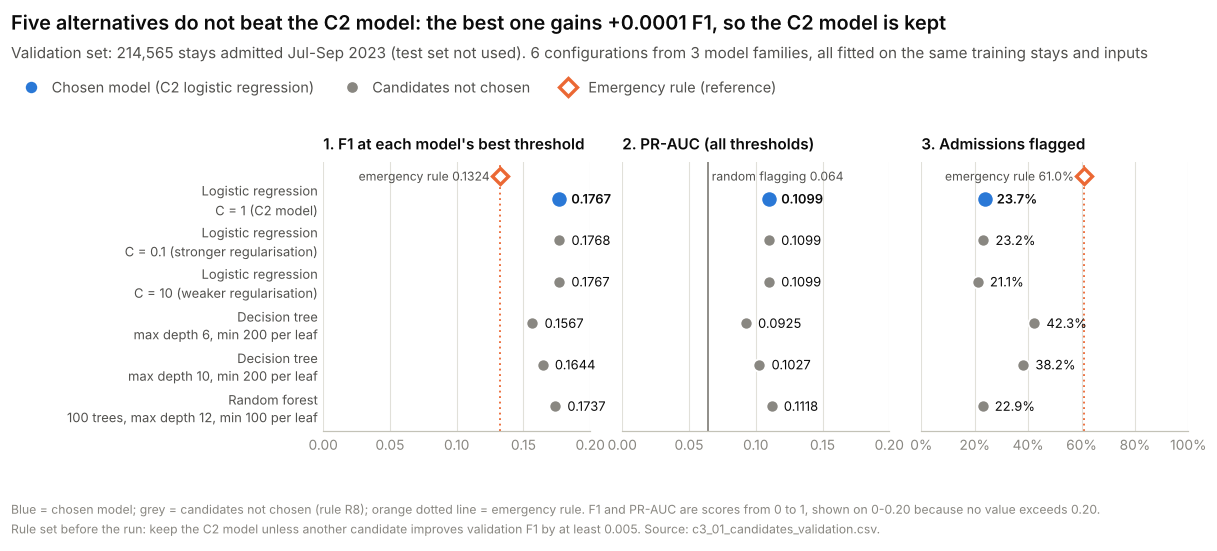

In [13]:
def v_models():
    d = cmp_val.copy()
    order = d.index.tolist()[::-1]
    y = {k: i for i, k in enumerate(order)}
    fig, axes = plt.subplots(1, 3, figsize=(11, 5.0), gridspec_kw=dict(width_ratios=[1, 1, 1], wspace=S.PANEL_GAP))
    fig.subplots_adjust(left=0.27, right=0.985, top=0.70, bottom=0.21)
    panels = [(axes[0], "F1", (0, 0.20), "1. F1 at each model's best threshold", REF_VAL["F1"], lambda v: f"{v:.4f}"),
              (axes[1], "PR-AUC (average precision)", (0, 0.20), "2. PR-AUC (all thresholds)", float(y_va.mean()), lambda v: f"{v:.4f}"),
              (axes[2], "flagged %", S.SCALE_SHARE, "3. Admissions flagged", REF_VAL["flagged %"], lambda v: S.pct(v))]
    for ax, col, lim, title, ref, fmt in panels:
        for k in order:
            v = d.loc[k, col]; chosen = (k == CHOSEN)
            mk = {**S.MODEL_MARKER, "markersize": 11} if chosen else dict(marker="o", markersize=8, markerfacecolor=S.REFERENCE,
                                                                         markeredgecolor=S.SURFACE, markeredgewidth=1.2)
            ax.plot(v, y[k], linestyle="none", zorder=3, **mk)
            ax.annotate(fmt(v), (v, y[k]), xytext=(8, -3), textcoords="offset points", fontsize=S.SIZE_NOTE + 0.5,
                        color=S.INK, fontweight="semibold" if chosen else "normal")
        if col == "PR-AUC (average precision)":
            ax.axvline(ref, color=S.REFERENCE, lw=1.2, zorder=0)
            ax.text(ref, len(order) - 0.45, f" random flagging {ref:.3f}", fontsize=S.SIZE_NOTE, color=S.INK2, va="center")
        else:
            ax.axvline(ref, color=S.RULE, lw=1.2, zorder=0, ls=(0, (1, 2)))
            ax.plot(ref, len(order) - 0.45, linestyle="none", **{**S.RULE_MARKER, "markersize": 7})
            ax.text(ref, len(order) - 0.45, f"emergency rule {fmt(ref)}   ", fontsize=S.SIZE_NOTE, color=S.INK2, va="center", ha="right")
        if lim == S.SCALE_SHARE:
            S.percent_axis(ax, lim, "x")
        else:
            ax.set_xlim(lim); ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20]); ax.grid(axis="y", visible=False)
        ax.set_ylim(-0.6, len(order) - 0.1); ax.set_yticks(range(len(order)))
        ax.set_title(title, fontsize=S.SIZE_PANEL); ax.spines["bottom"].set_visible(True)
        ax.set_yticklabels([k.replace(", ", "\n", 1) if ax is axes[0] else "" for k in order], linespacing=1.2, fontsize=S.SIZE_NOTE + 0.5)
    gain = cmp_val.F1.max() - cmp_val.loc[C2_NAME, "F1"]
    S.frame(fig,
            f"Five alternatives do not beat the C2 model: the best one gains {gain:+.4f} F1, so the C2 model is kept",
            f"Validation set: {S.num(len(y_va))} stays admitted Jul-Sep 2023 (test set not used). 6 configurations from 3 model families, all fitted on the same training stays and inputs",
            "Blue = chosen model; grey = candidates not chosen (rule R8); orange dotted line = emergency rule. F1 and PR-AUC are scores from 0 to 1, shown on 0-0.20 because no value exceeds 0.20.\n"
            "Rule set before the run: keep the C2 model unless another candidate improves validation F1 by at least 0.005. Source: c3_01_candidates_validation.csv.",
            legend_items=[Line2D([], [], linestyle="none", label="Chosen model (C2 logistic regression)", **S.MODEL_MARKER),
                          Line2D([], [], linestyle="none", marker="o", markersize=8, markerfacecolor=S.REFERENCE, markeredgecolor=S.SURFACE, label="Candidates not chosen"),
                          Line2D([], [], linestyle="none", label="Emergency rule (reference)", **S.RULE_MARKER)])
    return fig
fig_m = v_models(); fig_m.savefig(FIG/"c3_fig1_model_comparison.png"); plt.show()

### 7.2 View 2 · Does the model beat the emergency rule? (test)

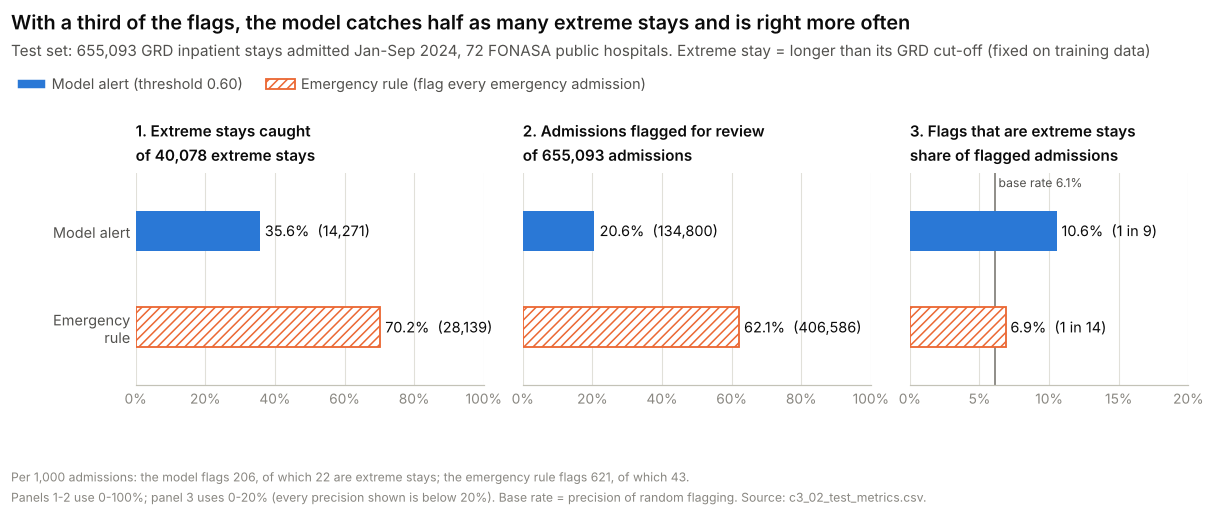

In [14]:
def v_rules():
    TM, TB = test_tab.iloc[0], test_tab.iloc[1]
    N_TEST, POS_TEST = len(y_te), int(y_te.sum())
    rows = [("model", TM, S.MODEL), ("rule", TB, S.RULE)]
    caught = {k: r.TP / POS_TEST * 100 for k, r, _ in rows}
    flagged = {k: (r.TP + r.FP) / N_TEST * 100 for k, r, _ in rows}
    hit = {k: r.TP / (r.TP + r.FP) * 100 for k, r, _ in rows}
    base_rate = POS_TEST / N_TEST * 100
    per1000 = {k: ((r.TP + r.FP) / N_TEST * 1000, r.TP / N_TEST * 1000) for k, r, _ in rows}
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.7), gridspec_kw=dict(width_ratios=[1, 1, 0.8], wspace=S.PANEL_GAP))
    fig.subplots_adjust(left=0.115, right=0.985, top=0.66, bottom=0.25)
    ypos = {"model": 1, "rule": 0}
    panels = [(axes[0], caught, S.SCALE_SHARE, f"1. Extreme stays caught\nof {S.num(POS_TEST)} extreme stays", lambda k, r: f"{S.pct(caught[k])}  ({S.num(r.TP)})"),
              (axes[1], flagged, S.SCALE_SHARE, f"2. Admissions flagged for review\nof {S.num(N_TEST)} admissions", lambda k, r: f"{S.pct(flagged[k])}  ({S.num(r.TP + r.FP)})"),
              (axes[2], hit, S.SCALE_PRECISION, "3. Flags that are extreme stays\nshare of flagged admissions", lambda k, r: f"{S.pct(hit[k])}  (1 in {(r.TP + r.FP) / r.TP:.0f})")]
    for ax, vals, lim, title, lab in panels:
        for k, r, col in rows:
            if k == "model":
                ax.barh(ypos[k], vals[k], height=0.42, color=col, edgecolor=S.SURFACE, linewidth=0)
            else:
                ax.barh(ypos[k], vals[k], height=0.42, color=S.SURFACE, edgecolor=col, hatch=S.RULE_HATCH, linewidth=1.2)
            ax.text(vals[k] + (lim[1] - lim[0]) * 0.015, ypos[k], lab(k, r), va="center", fontsize=S.SIZE_LABEL, color=S.INK)
        S.percent_axis(ax, lim, "x")
        ax.set_ylim(-0.6, 1.6); ax.set_yticks([1, 0]); ax.set_title(title, fontsize=S.SIZE_PANEL, linespacing=1.3)
        ax.spines["bottom"].set_visible(True)
        ax.set_yticklabels(["Model alert", "Emergency\nrule"] if ax is axes[0] else [])
    axes[2].axvline(base_rate, color=S.REFERENCE, lw=1.2, zorder=0)
    axes[2].text(base_rate, 1.5, f" base rate {S.pct(base_rate)}", fontsize=S.SIZE_NOTE, color=S.INK2, va="center")
    S.frame(fig,
            "With a third of the flags, the model catches half as many extreme stays and is right more often",
            f"Test set: {S.num(N_TEST)} GRD inpatient stays admitted Jan-Sep 2024, 72 FONASA public hospitals. Extreme stay = longer than its GRD cut-off (fixed on training data)",
            f"Per 1,000 admissions: the model flags {per1000['model'][0]:.0f}, of which {per1000['model'][1]:.0f} are extreme stays; the emergency rule flags {per1000['rule'][0]:.0f}, of which {per1000['rule'][1]:.0f}.\n"
            "Panels 1-2 use 0-100%; panel 3 uses 0-20% (every precision shown is below 20%). Base rate = precision of random flagging. Source: c3_02_test_metrics.csv.",
            legend_items=S.bar_legend_items())
    return fig
fig_r = v_rules(); fig_r.savefig(FIG/"c3_fig2_rules_compared_test.png"); plt.show()

### 7.3 View 3 · How much workload buys how much coverage? (validation, with the test point)

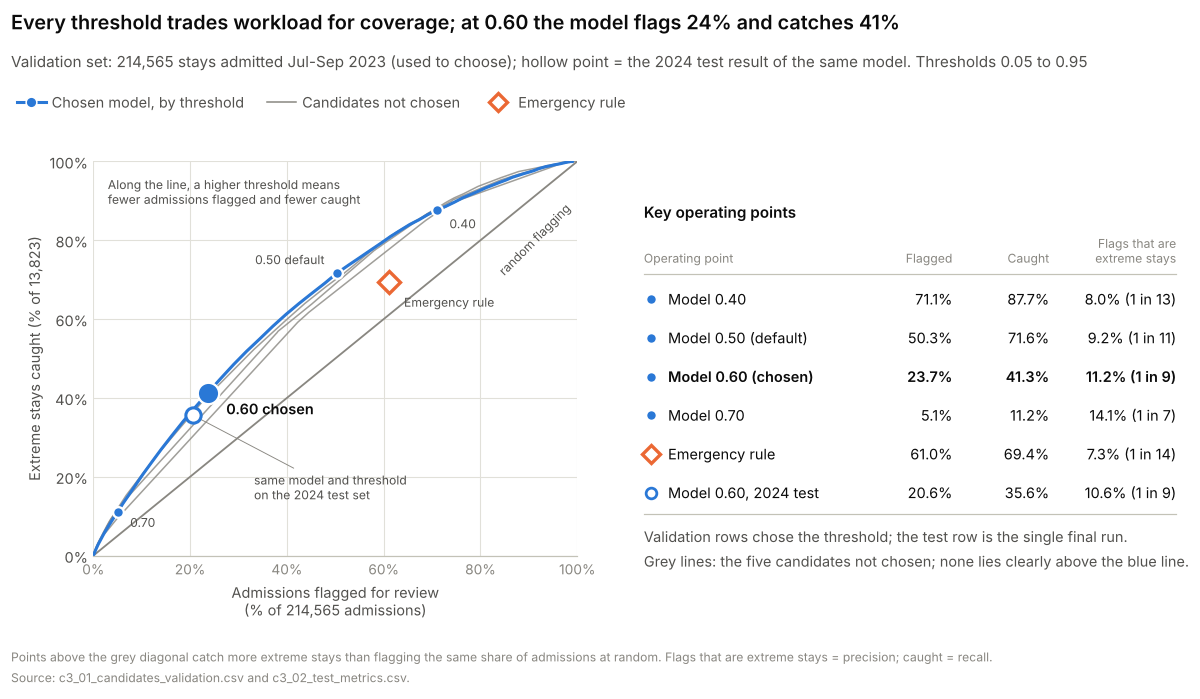

In [15]:
def v_tradeoff():
    fig = plt.figure(figsize=(11, 6.4))
    ax = fig.add_axes([0.08, 0.20, 0.40, 0.56])
    ax.plot([0, 100], [0, 100], color=S.REFERENCE, lw=1.2, zorder=1)
    ax.text(97, 90, "random flagging", fontsize=S.SIZE_NOTE, color=S.INK2, ha="right", va="top", rotation=45, rotation_mode="anchor")
    for k, cv in CURVES.items():                      # rule R8: candidates not chosen in grey
        if k != CHOSEN:
            ax.plot(cv["flagged %"], cv.recall*100, color=S.REFERENCE, lw=1, alpha=0.8, zorder=1.5)
    c = CURVES[CHOSEN].assign(flag=lambda d: d["flagged %"], caught=lambda d: d.recall*100)
    at = lambda t: c.loc[np.isclose(c.threshold, t)].iloc[0]
    ax.plot(c.flag, c.caught, color=S.MODEL, lw=2, zorder=2, solid_capstyle="round")
    for t, lab, off, ha in [(0.40, "0.40", (8, -12), "left"), (0.50, "0.50 default", (-8, 6), "right"), (0.70, "0.70", (8, -10), "left")]:
        r = at(t)
        ax.plot(r.flag, r.caught, linestyle="none", zorder=3, **{**S.MODEL_MARKER, "markersize": 7})
        ax.annotate(lab, (r.flag, r.caught), xytext=off, textcoords="offset points", ha=ha, fontsize=S.SIZE_NOTE, color=S.INK2)
    r = at(THRESHOLD)
    ax.plot(r.flag, r.caught, linestyle="none", zorder=4, **{**S.MODEL_MARKER, "markersize": 14})
    ax.annotate(f"{THRESHOLD:.2f} chosen", (r.flag, r.caught), xytext=(12, -14), textcoords="offset points",
                fontsize=S.SIZE_LABEL, color=S.INK, fontweight="semibold")
    TM = test_tab.iloc[0]
    tf, tc = TM["flagged %"], TM.recall*100
    ax.plot(tf, tc, linestyle="none", zorder=4, marker="o", markersize=10, markerfacecolor=S.SURFACE, markeredgecolor=S.MODEL, markeredgewidth=2)
    ax.annotate("same model and threshold\non the 2024 test set", (tf, tc), xytext=(40, -55), textcoords="offset points", ha="left",
                fontsize=S.SIZE_NOTE, color=S.INK2, arrowprops=dict(arrowstyle="-", color=S.MUTED, lw=0.6))
    b_flag, b_caught = REF_VAL["flagged %"], REF_VAL["recall"]*100
    ax.plot(b_flag, b_caught, linestyle="none", zorder=4, **{**S.RULE_MARKER, "markersize": 10})
    ax.annotate("Emergency rule", (b_flag, b_caught), xytext=(10, -16), textcoords="offset points", fontsize=S.SIZE_NOTE, color=S.INK2)
    ax.text(3, 96, "Along the line, a higher threshold means\nfewer admissions flagged and fewer caught", fontsize=S.SIZE_NOTE, color=S.INK2, va="top")
    S.percent_axis(ax, S.SCALE_SHARE, "x"); S.percent_axis(ax, S.SCALE_SHARE, "y")
    ax.grid(axis="both", visible=True); ax.spines["bottom"].set_visible(True)
    ax.set_xlabel(f"Admissions flagged for review\n(% of {S.num(len(y_va))} admissions)")
    ax.set_ylabel(f"Extreme stays caught (% of {S.num(int(y_va.sum()))})")
    x0, y0, dy = 0.535, 0.60, 0.055
    fig.text(0.535, 0.68, "Key operating points", fontsize=S.SIZE_PANEL, fontweight="semibold", color=S.INK)
    for x, h, ha in [(0.535, "Operating point", "left"), (0.79, "Flagged", "right"), (0.87, "Caught", "right"), (0.975, "Flags that are\nextreme stays", "right")]:
        fig.text(x, y0 + 0.012, h, fontsize=S.SIZE_NOTE, color=S.MUTED, ha=ha, va="bottom")
    fig.add_artist(Line2D([0.535, 0.975], [y0, y0], transform=fig.transFigure, color=S.AXIS, lw=0.8))
    table = [(f"Model {t:.2f}" + (" (default)" if t == 0.5 else " (chosen)" if t == THRESHOLD else ""), at(t).flag, at(t).caught, at(t).precision*100)
             for t in (0.40, 0.50, THRESHOLD, 0.70)]
    table.append(("Emergency rule", b_flag, b_caught, REF_VAL["precision"]*100))
    table.append((f"Model {THRESHOLD:.2f}, 2024 test", tf, tc, TM.precision*100))
    for i, (name, f, cg, pr) in enumerate(table):
        yy = y0 - dy*(i + 0.65); w = "semibold" if "chosen" in name else "normal"
        if name == "Emergency rule": mk = S.RULE_MARKER
        elif "test" in name: mk = dict(marker="o", markersize=7, markerfacecolor=S.SURFACE, markeredgecolor=S.MODEL, markeredgewidth=1.8)
        else: mk = {**S.MODEL_MARKER, "markersize": 7}
        fig.add_artist(Line2D([x0 + 0.006], [yy], transform=fig.transFigure, linestyle="none", **mk))
        fig.text(x0 + 0.02, yy, name, fontsize=S.SIZE_LABEL, color=S.INK, va="center", fontweight=w)
        fig.text(0.79, yy, S.pct(f), fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
        fig.text(0.87, yy, S.pct(cg), fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
        fig.text(0.975, yy, f"{S.pct(pr)} (1 in {100/pr:.0f})", fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
    fig.add_artist(Line2D([0.535, 0.975], [y0 - dy*6.2, y0 - dy*6.2], transform=fig.transFigure, color=S.AXIS, lw=0.8))
    fig.text(0.535, y0 - dy*6.5, "Validation rows chose the threshold; the test row is the single final run.\n"
             "Grey lines: the five candidates not chosen; none lies clearly above the blue line.", fontsize=S.SIZE_LABEL, color=S.INK2, va="top", linespacing=1.4)
    S.frame(fig, f"Every threshold trades workload for coverage; at {THRESHOLD:.2f} the model flags {S.pct(r.flag, 0)} and catches {S.pct(r.caught, 0)}",
            f"Validation set: {S.num(len(y_va))} stays admitted Jul-Sep 2023 (used to choose); hollow point = the 2024 test result of the same model. Thresholds 0.05 to 0.95",
            "Points above the grey diagonal catch more extreme stays than flagging the same share of admissions at random. Flags that are extreme stays = precision; caught = recall.\n"
            "Source: c3_01_candidates_validation.csv and c3_02_test_metrics.csv.",
            legend_items=[Line2D([], [], color=S.MODEL, lw=2, label="Chosen model, by threshold", marker="o", markersize=7, markerfacecolor=S.MODEL, markeredgecolor=S.SURFACE),
                          Line2D([], [], color=S.REFERENCE, lw=1, label="Candidates not chosen"),
                          Line2D([], [], linestyle="none", label="Emergency rule", **S.RULE_MARKER)])
    return fig
fig_t = v_tradeoff(); fig_t.savefig(FIG/"c3_fig3_threshold_tradeoff.png"); plt.show()

### 7.4 View 4 · In which admission types does the alert work? (test)

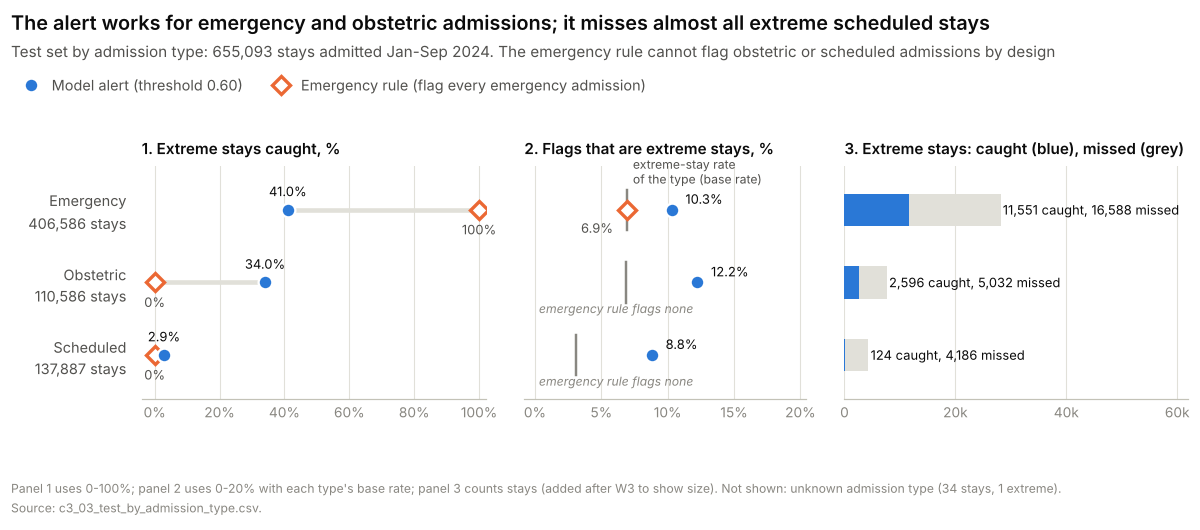

In [16]:
def v_types():
    order = ["URGENCIA", "OBSTETRICA", "PROGRAMADA"]
    d = seg.loc[order].copy()
    y = {k: i for i, k in enumerate(reversed(order))}
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), gridspec_kw=dict(width_ratios=[1.1, 0.9, 1.1], wspace=S.PANEL_GAP))
    fig.subplots_adjust(left=0.12, right=0.985, top=0.68, bottom=0.24)
    a, b, c = axes
    for k in order:
        r = d.loc[k]
        a.plot([r["model recall %"], r["rule recall %"]], [y[k], y[k]], color=S.GRID, lw=3, zorder=1, solid_capstyle="round")
        a.plot(r["rule recall %"], y[k], linestyle="none", zorder=3, **S.RULE_MARKER)
        a.plot(r["model recall %"], y[k], linestyle="none", zorder=4, **S.MODEL_MARKER)
        a.annotate(S.pct(r["model recall %"]), (r["model recall %"], y[k]), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=S.SIZE_NOTE + 0.5, color=S.INK)
        a.annotate(S.pct(r["rule recall %"], 0), (r["rule recall %"], y[k]), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=S.SIZE_NOTE + 0.5, color=S.INK2)
        b.plot([r["extreme-stay rate %"]]*2, [y[k] - 0.28, y[k] + 0.28], color=S.REFERENCE, lw=1.6, zorder=1)
        b.plot(r["model precision %"], y[k], linestyle="none", zorder=4, **S.MODEL_MARKER)
        b.annotate(S.pct(r["model precision %"]), (r["model precision %"], y[k]), xytext=(9, 4), textcoords="offset points", fontsize=S.SIZE_NOTE + 0.5, color=S.INK)
        if r["rule flags"] > 0:
            b.plot(r["rule precision %"], y[k], linestyle="none", zorder=3, **S.RULE_MARKER)
            b.annotate(S.pct(r["rule precision %"]), (r["rule precision %"], y[k]), xytext=(-9, -15), textcoords="offset points", ha="right", fontsize=S.SIZE_NOTE + 0.5, color=S.INK2)
        else:
            b.text(0.3, y[k] - 0.36, "emergency rule flags none", fontsize=S.SIZE_NOTE, color=S.MUTED, va="center", style="italic")
        c.barh(y[k], r["caught by model"], height=0.45, color=S.MODEL, edgecolor=S.SURFACE, linewidth=0)
        c.barh(y[k], r["missed by model"], left=r["caught by model"], height=0.45, color=S.GRID, edgecolor=S.SURFACE, linewidth=0)
        c.text(r["extreme stays"] + 400, y[k], f"{S.num(r['caught by model'])} caught, {S.num(r['missed by model'])} missed", va="center", fontsize=S.SIZE_NOTE + 0.5, color=S.INK)
    b.annotate("extreme-stay rate\nof the type (base rate)", (d.loc["URGENCIA", "extreme-stay rate %"], y["URGENCIA"] + 0.28), xytext=(4, 2), textcoords="offset points", fontsize=S.SIZE_NOTE, color=S.INK2, va="bottom")
    for ax, lim, title in [(a, S.SCALE_SHARE, "1. Extreme stays caught, %"), (b, S.SCALE_PRECISION, "2. Flags that are extreme stays, %")]:
        S.percent_axis(ax, lim, "x"); ax.set_xlim(lim[0] - (lim[1]-lim[0])*0.04, lim[1] + (lim[1]-lim[0])*0.02)
    c.set_xlim(0, 62000); c.set_xticks([0, 20000, 40000, 60000]); c.set_xticklabels(["0", "20k", "40k", "60k"]); c.grid(axis="y", visible=False)
    c.set_title("3. Extreme stays: caught (blue), missed (grey)", fontsize=S.SIZE_PANEL)
    for ax in axes:
        ax.set_ylim(-0.6, len(order) - 0.4); ax.set_yticks(range(len(order))); ax.spines["bottom"].set_visible(True); ax.tick_params(axis="y", pad=10)
    a.set_title("1. Extreme stays caught, %", fontsize=S.SIZE_PANEL); b.set_title("2. Flags that are extreme stays, %", fontsize=S.SIZE_PANEL)
    a.set_yticklabels([f"{S.ADMISSION_TYPE_EN[k]}\n{S.num(d.loc[k, 'stays'])} stays" for k in reversed(order)], linespacing=1.3)
    b.set_yticklabels([]); c.set_yticklabels([])
    unk = seg.loc["DESCONOCIDO"]
    S.frame(fig, "The alert works for emergency and obstetric admissions; it misses almost all extreme scheduled stays",
            f"Test set by admission type: {S.num(len(y_te))} stays admitted Jan-Sep 2024. The emergency rule cannot flag obstetric or scheduled admissions by design",
            f"Panel 1 uses 0-100%; panel 2 uses 0-20% with each type's base rate; panel 3 counts stays (added after W3 to show size). "
            f"Not shown: unknown admission type ({S.num(unk.stays)} stays, {int(unk['extreme stays'])} extreme).\n"
            "Source: c3_03_test_by_admission_type.csv.")
    return fig
fig_y = v_types(); fig_y.savefig(FIG/"c3_fig4_admission_types_test.png"); plt.show()

### 7.5 Presentation versions of the final views

The slides use these versions: the same values and rules (R1-R8), with larger text and fewer labels, because on a slide the title states the claim and the speakers give the context. They are saved in `outputs/figures/slides/`.

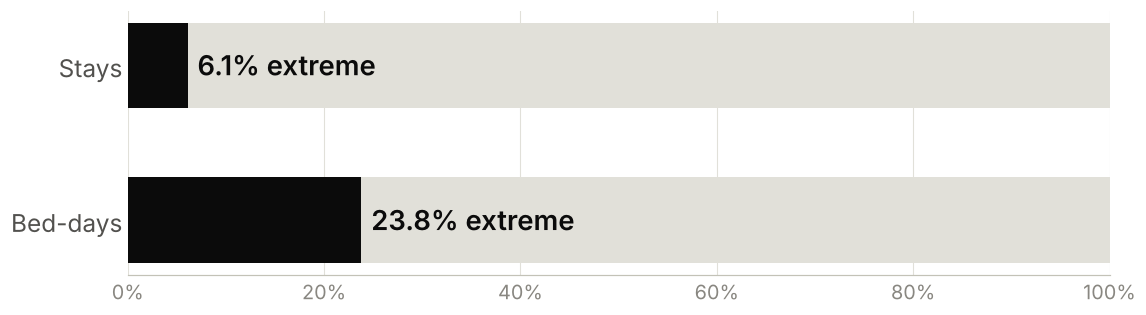

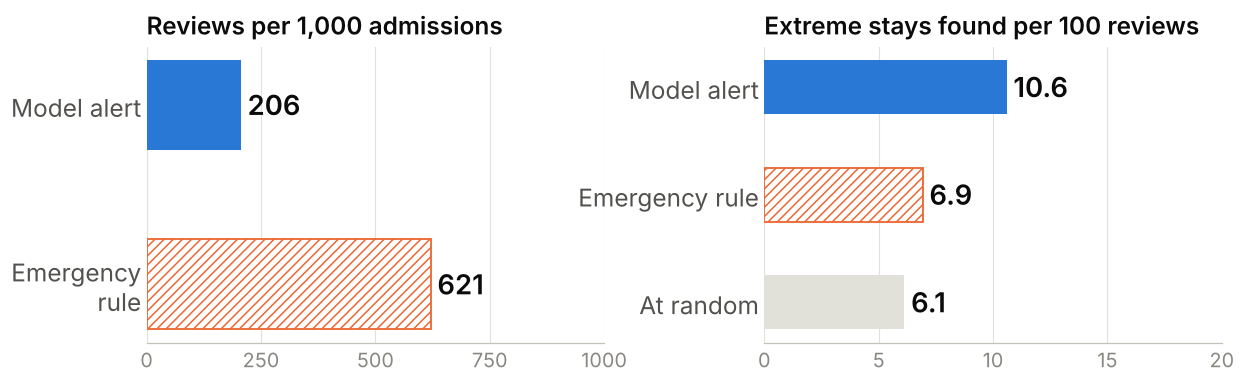

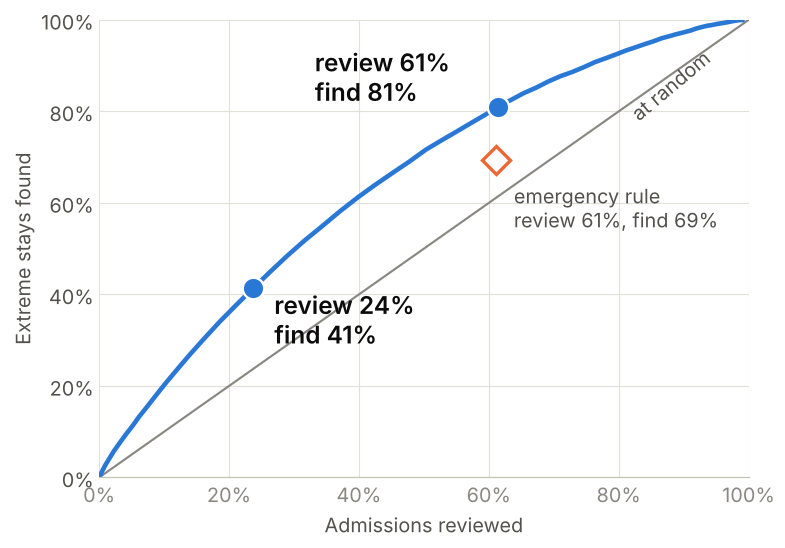

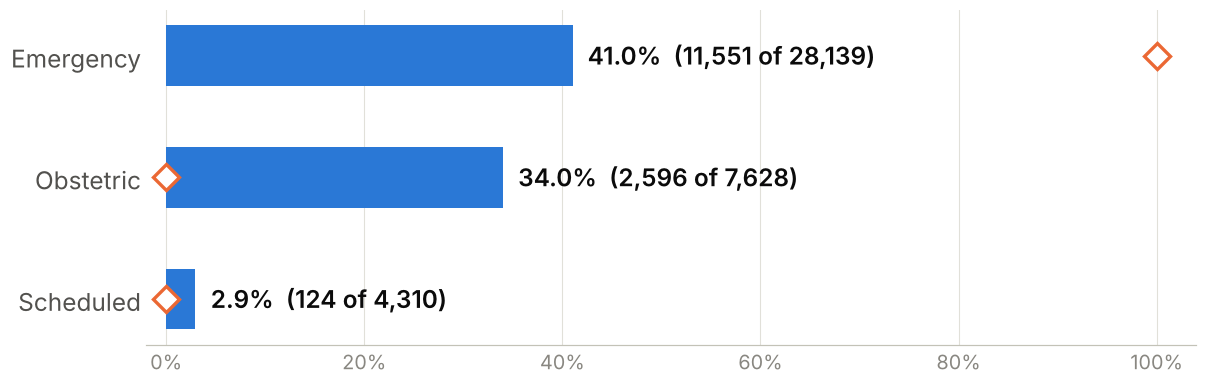

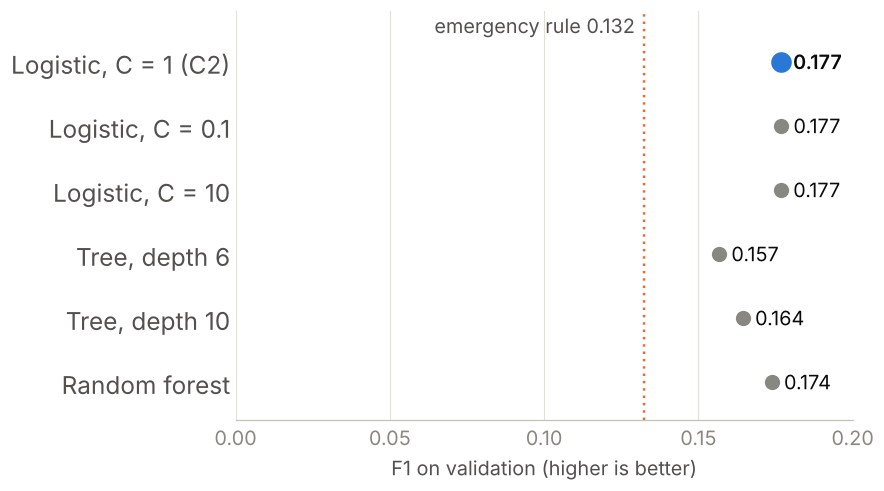

In [17]:
# Presentation versions of the final views: same rules R1-R8, same values, larger text and fewer labels,
# because on a slide the title states the claim and the speaker gives the context.
SLIDE = dict(label=16, tick=13, note=13)
SL = FIG / "slides"; SL.mkdir(exist_ok=True)

def _clean(ax):
    ax.tick_params(axis="x", labelsize=SLIDE["tick"]); ax.tick_params(axis="y", labelsize=SLIDE["label"])
    ax.spines["bottom"].set_visible(True)

def s1_hook():
    st, bd = float(impact.loc["extreme stays, % of stays", "value"]), float(impact.loc["extreme stays, % of bed-days", "value"])
    fig, ax = plt.subplots(figsize=(10.5, 3.2)); fig.subplots_adjust(left=0.13, right=0.98, top=0.95, bottom=0.2)
    for y, v, lab in [(1, st, "Stays"), (0, bd, "Bed-days")]:
        ax.barh(y, v, height=0.55, color=S.INK, edgecolor=S.SURFACE, linewidth=0)
        ax.barh(y, 100 - v, left=v, height=0.55, color=S.GRID, edgecolor=S.SURFACE, linewidth=0)
        ax.text(v + 1, y, f"{S.pct(v)} extreme", va="center", fontsize=SLIDE["label"] + 2, color=S.INK, fontweight="semibold")
    ax.set_yticks([1, 0]); ax.set_yticklabels(["Stays", "Bed-days"]); S.percent_axis(ax, S.SCALE_SHARE, "x"); _clean(ax)
    return fig

def s2_reviews():
    TM, TB = test_tab.iloc[0], test_tab.iloc[1]; N = len(y_te)
    rev = {"model": (TM.TP + TM.FP) / N * 1000, "rule": (TB.TP + TB.FP) / N * 1000}
    hit = {"model": TM.precision * 100, "rule": TB.precision * 100, "random": y_te.mean() * 100}
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw=dict(wspace=0.35))
    fig.subplots_adjust(left=0.12, right=0.97, top=0.86, bottom=0.17)
    for y, k in [(1, "model"), (0, "rule")]:
        if k == "model": a.barh(y, rev[k], height=0.5, color=S.MODEL, linewidth=0)
        else: a.barh(y, rev[k], height=0.5, color=S.SURFACE, edgecolor=S.RULE, hatch=S.RULE_HATCH, linewidth=1.2)
        a.text(rev[k] + 15, y, f"{rev[k]:.0f}", va="center", fontsize=SLIDE["label"] + 2, fontweight="semibold", color=S.INK)
    a.set_xlim(0, 1000); a.set_xticks([0, 250, 500, 750, 1000]); a.grid(axis="y", visible=False)
    a.set_yticks([1, 0]); a.set_yticklabels(["Model alert", "Emergency\nrule"]); _clean(a)
    a.set_title("Reviews per 1,000 admissions", fontsize=SLIDE["label"], loc="left")
    for y, k in [(2, "model"), (1, "rule"), (0, "random")]:
        if k == "model": b.barh(y, hit[k], height=0.5, color=S.MODEL, linewidth=0)
        elif k == "rule": b.barh(y, hit[k], height=0.5, color=S.SURFACE, edgecolor=S.RULE, hatch=S.RULE_HATCH, linewidth=1.2)
        else: b.barh(y, hit[k], height=0.5, color=S.GRID, linewidth=0)
        b.text(hit[k] + 0.3, y, f"{hit[k]:.1f}", va="center", fontsize=SLIDE["label"] + 2, fontweight="semibold", color=S.INK)
    b.set_xlim(0, 20); b.set_xticks([0, 5, 10, 15, 20]); b.grid(axis="y", visible=False)
    b.set_yticks([2, 1, 0]); b.set_yticklabels(["Model alert", "Emergency rule", "At random"]); _clean(b)
    b.set_title("Extreme stays found per 100 reviews", fontsize=SLIDE["label"], loc="left")
    return fig

def s3_capacity():
    c = CURVES[CHOSEN]; at = lambda t: c.loc[np.isclose(c.threshold, t)].iloc[0]
    fig, ax = plt.subplots(figsize=(7.2, 5.2)); fig.subplots_adjust(left=0.15, right=0.97, top=0.97, bottom=0.17)
    ax.plot([0, 100], [0, 100], color=S.REFERENCE, lw=1.4)
    ax.text(88, 78, "at random", fontsize=SLIDE["note"], color=S.INK2, rotation=40, ha="center")
    ax.plot(c["flagged %"], c.recall * 100, color=S.MODEL, lw=3)
    for t, txt, off in [(0.60, "review 24%\nfind 41%", (14, -36)), (0.45, "review 61%\nfind 81%", (-120, 4))]:
        r = at(t); ax.plot(r["flagged %"], r.recall * 100, linestyle="none", **{**S.MODEL_MARKER, "markersize": 14})
        ax.annotate(txt, (r["flagged %"], r.recall * 100), xytext=off, textcoords="offset points", fontsize=SLIDE["label"], fontweight="semibold", color=S.INK)
    ax.plot(REF_VAL["flagged %"], REF_VAL["recall"] * 100, linestyle="none", **{**S.RULE_MARKER, "markersize": 13})
    ax.annotate("emergency rule\nreview 61%, find 69%", (REF_VAL["flagged %"], REF_VAL["recall"] * 100), xytext=(12, -44),
                textcoords="offset points", fontsize=SLIDE["note"], color=S.INK2)
    S.percent_axis(ax, S.SCALE_SHARE, "x"); S.percent_axis(ax, S.SCALE_SHARE, "y"); ax.grid(axis="both", visible=True); _clean(ax)
    ax.tick_params(axis="y", labelsize=SLIDE["tick"])
    ax.set_xlabel("Admissions reviewed", fontsize=SLIDE["note"]); ax.set_ylabel("Extreme stays found", fontsize=SLIDE["note"])
    return fig

def s4_types():
    order = ["URGENCIA", "OBSTETRICA", "PROGRAMADA"]; d = seg.loc[order]
    fig, ax = plt.subplots(figsize=(11.5, 3.9)); fig.subplots_adjust(left=0.14, right=0.97, top=0.95, bottom=0.17)
    for y, k in zip([2, 1, 0], order):
        r = d.loc[k]
        ax.barh(y, r["model recall %"], height=0.5, color=S.MODEL, linewidth=0)
        ax.plot(r["rule recall %"], y, linestyle="none", zorder=4, **{**S.RULE_MARKER, "markersize": 12})
        ax.text(max(r["model recall %"], 3) + 1.5, y, f"{S.pct(r['model recall %'])}  ({S.num(r['caught by model'])} of {S.num(r['extreme stays'])})",
                va="center", fontsize=SLIDE["label"], fontweight="semibold", color=S.INK)
    ax.set_yticks([2, 1, 0]); ax.set_yticklabels([S.ADMISSION_TYPE_EN[k] for k in order]); S.percent_axis(ax, S.SCALE_SHARE, "x")
    ax.set_xlim(-2, 104); _clean(ax)
    return fig

def s5_models():
    short = {C2_NAME: "Logistic, C = 1 (C2)", "Logistic regression, C = 0.1 (stronger regularisation)": "Logistic, C = 0.1",
             "Logistic regression, C = 10 (weaker regularisation)": "Logistic, C = 10", "Decision tree, max depth 6, min 200 per leaf": "Tree, depth 6",
             "Decision tree, max depth 10, min 200 per leaf": "Tree, depth 10", "Random forest, 100 trees, max depth 12, min 100 per leaf": "Random forest"}
    order = list(cmp_val.index)[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 4.6)); fig.subplots_adjust(left=0.3, right=0.96, top=0.95, bottom=0.14)
    for y, k in enumerate(order):
        v = cmp_val.loc[k, "F1"]; ch = k == CHOSEN
        mk = {**S.MODEL_MARKER, "markersize": 15} if ch else dict(marker="o", markersize=11, markerfacecolor=S.REFERENCE, markeredgecolor=S.SURFACE)
        ax.plot(v, y, linestyle="none", **mk)
        ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=SLIDE["note"], color=S.INK, fontweight="semibold" if ch else "normal")
    ax.axvline(REF_VAL["F1"], color=S.RULE, lw=1.6, ls=(0, (1, 2)))
    ax.text(REF_VAL["F1"] - 0.003, len(order) - 0.55, f"emergency rule {REF_VAL['F1']:.3f}", ha="right", fontsize=SLIDE["note"], color=S.INK2)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([short[k] for k in order]); ax.set_ylim(-0.6, len(order) - 0.2)
    ax.set_xlim(0, 0.20); ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20]); ax.grid(axis="y", visible=False); _clean(ax)
    ax.set_xlabel("F1 on validation (higher is better)", fontsize=SLIDE["note"])
    return fig

for name, fn in [("s1_hook", s1_hook), ("s2_reviews", s2_reviews), ("s3_capacity", s3_capacity), ("s4_types", s4_types), ("s5_models", s5_models)]:
    f = fn(); f.savefig(SL / f"c3_{name}.png", dpi=200); plt.show()

## 8. Conclusions, recommendation and limits

**Observed (test set, 655,093 stays admitted Jan-Sep 2024, extreme-stay rate 6.1%).**
- The model alert flags 20.6% of admissions and catches 35.6% of extreme stays; 10.6% of its flags are extreme stays (about 1 in 9).
- The emergency rule flags 62.1% and catches 70.2%; 6.9% of its flags are extreme stays (about 1 in 14), close to the 6.1% base rate.
- Per 1,000 admissions, the model flags 206, of which 22 are extreme stays; the rule flags 621, of which 43.
- None of the five alternatives improved validation F1 by more than 0.0001, so the C2 model was kept; trees reached lower F1 and flagged more admissions.
- The model catches 41.0% of extreme emergency stays and 34.0% of extreme obstetric stays, but only 2.9% of extreme scheduled stays (124 of 4,310).

**Interpretation.**
- The model concentrates review effort: its flags are extreme stays more often than the rule's, but it misses more of them at the chosen threshold. Which is better depends on how many admissions a discharge team can review, which the data do not tell us.
- On validation, at a workload close to the rule's (61.4% flagged, threshold 0.45), the model caught 81.0% of extreme stays against the rule's 69.4%. This was not tested on 2024 data, so it is a lead, not a result.
- Admission-time fields carry weak signal (C2): most of what makes a stay extreme appears after admission.

**Recommendation (conditional).** If a hospital's discharge team can review about one admission in five, use the model alert at 0.60 instead of the emergency rule, as a prioritisation aid, not as a decision about any patient; do not rely on it for scheduled admissions. If the team can review more, choose a lower threshold per hospital on validation data and confirm it on new data before use. The evidence does not support using the alert to decide care for individual patients.

**Limits.**
- The label is defined by GRD cut-offs from discharge coding: it says a stay was long for its GRD, not that it was avoidable.
- Public data from one national network, 2023-2024; performance per hospital, costs of each error and capacity of each team were not available.
- The comparison covers 3 model families with few settings; no cross-validation over time was run beyond the fixed validation period.
- Observed associations (for example, admission type) are not causes.

## 9. Decision record, feedback use, W3 design selection, contributions and AI use

### 9.1 Main decisions and their evidence

| # | Stage | Decision | Reason and evidence | Where to see it |
|---|---|---|---|---|
| 1 | W1 | Follow candidate B (length of stay and extreme stays), not candidate A (out-of-region stays) | A affected 2.3% of stays with a denominator that is not population-based; B gave a stable hospital signal between years | `GROUP_01_W1/report/GROUP_01_Report.pdf`; W1 notebook sections 4-5 |
| 2 | W1-C1 | Parse each file with its own encoding and date format; GRD weight with decimal comma | The two FONASA files differ in format | Data card (section 1); C1 notebook 1.3 |
| 3 | C1 | Inpatient stays only; exclude invalid dates and GRD codes; keep repeats and same-day stays | CMA is a different activity; exclusions remove 52 + 45 + 16 inpatient rows | Section 3; C1 notebook 3 |
| 4 | C1 | Extreme stay = LOS > Q3 + 1.5 × IQR within GRD code, base-GRD fallback under 30 cases | Case-mix adjustment; sensitivity checked in C1 section 5 | Section 4.1; C1 notebook 4-5 |
| 5 | W2 | Refit the cut-offs on training stays only and freeze them | C1 cut-offs used the future test period (leakage audit) | Section 4.1; W2 notebook 5-6 |
| 6 | W2 | Chronological split with embargo and censoring | Evaluate on a later period, as the alert would be used | Section 4; W2 notebook 6 |
| 7 | W2 → C2 | Admission-time inputs only, with a guard | W2 feedback: no diagnoses or results unknown at admission | Section 4.2; C2 notebook 3 |
| 8 | C2 | Logistic regression with balanced classes; threshold by validation F1 (0.60); references: emergency rule and flag nobody | Simple, explainable model; accuracy is misleading at 6% prevalence (flag nobody scores 93.9%) | Sections 5-6; C2 notebook 4-6 |
| 9 | W3 | Visual system R1-R8 and three views that follow the decision (whether, how much, where) | Earlier C2 views needed mental arithmetic and mixed colour meanings | `GROUP_01_W3/report/GROUP_01_W3_Report.pdf`; section 7 |
| 10 | C3 | Compare 6 configurations from 3 families; keep the C2 model unless F1 improves by 0.005 | C2 feedback; no candidate improved meaningfully | Section 5, view 1 |
| 11 | C3 | Remove data files from the repository; keep links, versions and checksums | C3 rule: no data files | Section 1; README |

### 9.2 Feedback received and how it was used

| Stage feedback | What it asked | What we did | Where |
|---|---|---|---|
| W1 (97/100) | Add a README; close the definition of the stay benchmark | C1 added a package README and closed the benchmark definition and its limits | `GROUP_01_C1/README.md`, C1 notebook 4 |
| C1 (94/100) | README named correctly; review paths and packaging; state hypotheses before results | W2 checked paths and packaging in the notebook and stated hypotheses first | W2 notebook 1-2 |
| W2 (100/100) | Exclude fields not available at admission; freeze extreme-stay thresholds inside training | Both applied in C2 and kept here | Sections 4.1-4.2 |
| C2 (93.75/100) | Clearer presentation that connects the data to its purpose for the audience; report how many models were tried and compare 3 to 5 | External part of the C3 presentation built around the bed managers' decision; 6 configurations compared | Section 5; presentation |
| W3 | No feedback received at the time of C3 | — | — |

### 9.3 W3 design selection

The W3 views were selected because they follow the order of the decision the audience faces: whether the alert beats the rule (view 2), how much workload it costs (view 3) and where it works (view 4). C3 keeps them and their rules unchanged, adds the three improvements W3 itself proposed (per-1,000 line, test point on the trade-off, counts per admission type) and adds view 1 for the model comparison, using rule R8, which W3 defined in advance for extra candidates.

### 9.4 Contributions

| Member | Main contributions |
|---|---|
| Matías López | Graphs styling and visualization and data review and control |
| Cristóbal Ramírez | README, Notebook final views and other contents reviewed |

### 9.5 AI use

Claude (Anthropic) drafted code, notebooks, documents and slides in the earlier stages, as stated in each stage's AI-use section; in C3 it drafted the models comparison, the README and the presentation. We reviewed the graphs, the information used, and checked the numbers and calculations ran by AI so our work stays clean, we changed some conclusions and structured and designed the slides and data chart styles. Checks built into the pipeline: input checksums, split counts against W2, frozen cut-offs against W2 and C2, a leakage guard, and the test result against C2.